In [2]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.signal import StateSpace, lsim 

In [3]:
R = 1.0         # ohm           winding resistance
L = 0.5e-3      # H             winding inductance 
k = 0.05        # N*m/A         kt = ke = k
kt = ke = k
J = 1.0e-4      # kg*m^2        rotor inertia 
b = 1.0e-5      # n*m*s/rad     viscous friction 
V = 12.0        # v             Supply 

In [5]:
A = np.array ([
    [-R/L,  -ke/L,  0],
    [kt/J,  -b/J,   0],
    [0,     1,      0]
])

B = np.array([
    [1/L,   0],
    [0,     -1/J],
    [0,     0]
])

C = np.eye(3)

D = np.zeros((3,2))

sys = StateSpace(A,B,C,D)

In [9]:
# voltage steps from 0 to 12 at t=0 with no load. Then a load torque is applied 

t = np.linspace(0,0.4,4000)
tau_L = 0.2
u = np.zeros((len(t), 2))
u[:, 0] = V
u[t >= 0.2, 1] = tau_L
_, x, _ = lsim(sys, U=u, T=t)
i_t, w_t, th_t = x[:,0], x[:,1], x[:,2]

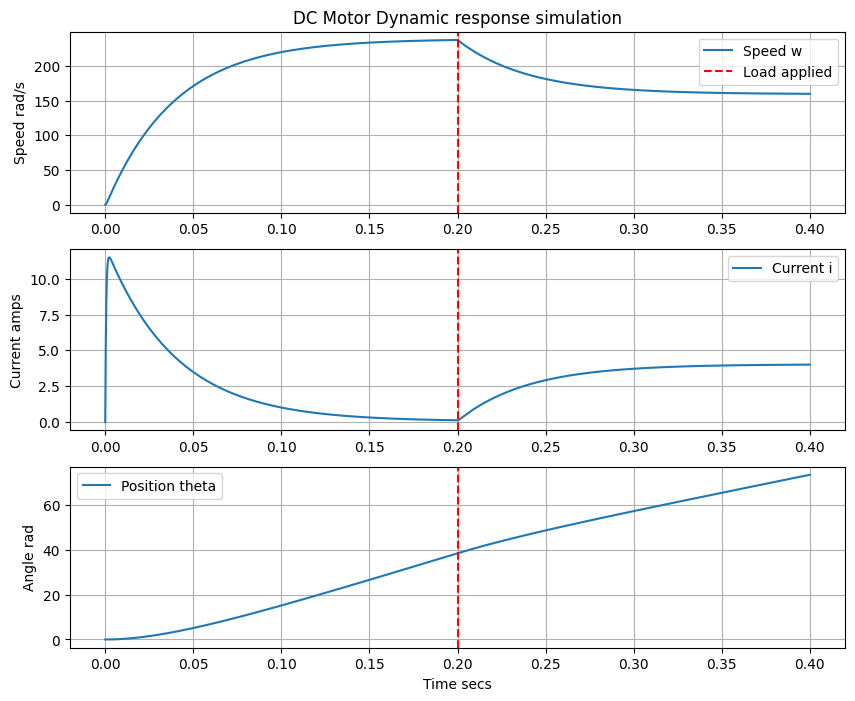

In [15]:
plt.figure(figsize=(10, 8))

plt.subplot(3,1,1)
plt.plot(t, w_t, label="Speed w")
plt.axvline(x=0.2, color="r", linestyle="--", label="Load applied")
plt.title("DC Motor Dynamic response simulation")
plt.ylabel("Speed rad/s")
plt.grid(True)
plt.legend()

plt.subplot(3,1,2)
plt.plot(t, i_t, label="Current i")
plt.axvline(x=0.2, color="r", linestyle="--")
plt.ylabel("Current amps")
plt.grid(True)
plt.legend()

plt.subplot(3,1,3)
plt.plot(t, th_t, label="Position theta")
plt.axvline(x=0.2, color="r", linestyle="--")
plt.ylabel("Angle rad")
plt.xlabel("Time secs")
plt.grid(True)
plt.legend()